In [2]:
import sys
import os
import glob

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

from tabpfn import TabPFNRegressor

## Processing superconductivity dataset

In [2]:
data_df = pd.read_csv("../data/superconductivity/train.csv", sep=",")
data_df.sample(5)

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
9942,5,62.383250,45.256604,53.597182,34.223675,1.498887,1.541343,72.90645,9.949583,26.592872,...,2.166667,2.352158,2.139826,1.589027,1.431139,1,0.750000,0.489898,0.372678,42.0
4507,4,64.237600,66.237945,48.636630,56.870706,1.143045,1.110848,121.32760,27.430055,45.423422,...,2.000000,2.000000,2.000000,1.386294,1.240684,0,0.727273,0.000000,0.000000,118.0
12074,2,113.905660,112.905668,111.128344,110.141012,0.668865,0.676664,49.99962,20.443584,24.999810,...,3.000000,3.000000,3.000000,0.693147,0.692347,0,0.120000,0.000000,0.000000,1.0
14058,2,98.509000,69.276333,44.867403,27.919603,0.212621,0.333865,175.39600,54.861667,87.698000,...,4.333333,4.582576,3.979057,0.610864,0.690186,4,0.333333,2.000000,1.885618,6.3
5235,9,56.514349,81.121210,27.245064,55.342151,1.700727,1.354168,207.97246,38.078826,60.664426,...,2.633786,2.316388,2.416769,2.099856,1.732827,4,0.908560,1.165343,1.214445,87.1


## Split in 5 splits

In [ ]:
for i in range(1, 6):
    print(f"Processing dataset with random seed {i}...")

    if not os.path.exists(f"../data/superconduct_{i}"):
        os.makedirs(f"../data/superconduct_{i}")

    rand_seed = i

    train_df, test_df = train_test_split(data_df, test_size=0.2, random_state=rand_seed)
    train_df, val_df = train_test_split(train_df, test_size=0.25, random_state=rand_seed)

    # normalize the data frame
    scalar = StandardScaler()
    X_train = scalar.fit_transform(train_df.drop(columns=["critical_temp"]))
    X_val = scalar.transform(val_df.drop(columns=["critical_temp"]))
    X_test = scalar.transform(test_df.drop(columns=["critical_temp"]))

    y_mean, y_std = train_df["critical_temp"].mean(), train_df["critical_temp"].std()
    y_train = (train_df["critical_temp"] - y_mean) / y_std
    y_val = (val_df["critical_temp"] - y_mean) / y_std
    y_test = (test_df["critical_temp"] - y_mean) / y_std

    # remerge into a single dataframe
    columns = train_df.drop(columns=["critical_temp"]).columns
    train_df = pd.DataFrame(X_train, columns=columns, index=train_df.index)
    train_df["target"] = y_train
    val_df = pd.DataFrame(X_val, columns=columns, index=val_df.index)
    val_df["target"] = y_val
    test_df = pd.DataFrame(X_test, columns=columns, index=test_df.index)
    test_df["target"] = y_test

    # save the dataframes to csv
    train_df.to_csv(f"../data/superconduct_{rand_seed}/train.csv", index=False)
    val_df.to_csv(f"../data/superconduct_{rand_seed}/val.csv", index=False)
    test_df.to_csv(f"../data/superconduct_{rand_seed}/test.csv", index=False)

## Lasso

In [50]:
def train_lasso_cv(train_df, test_df, cv=5, alphas=None):
    X_train = train_df.drop(columns="target")
    y_train = train_df["target"]
    X_test = test_df.drop(columns="target")
    y_test = test_df["target"]

    # Create pipeline with scaling and LassoCV
    lasso_pipeline = make_pipeline(
        StandardScaler(),
        LassoCV(alphas=alphas, cv=cv, max_iter=20000, random_state=42, fit_intercept=False),
    )

    # Fit model
    lasso_pipeline.fit(X_train, y_train)

    # Predict and evaluate
    y_pred = lasso_pipeline.predict(X_test)
    test_mse = mean_squared_error(y_test, y_pred)

    # Extract best alpha
    best_model = lasso_pipeline.named_steps["lassocv"]
    best_alpha = best_model.alpha_

    return best_model, best_alpha, test_mse

(12757, 82) (4253, 82)
(12757, 82) (4253, 82)
(12757, 82) (4253, 82)
(12757, 82) (4253, 82)
(12757, 82) (4253, 82)
Test MSE: 0.2747 ± 0.0061
Selected alpha: 0.0007 ± 0.0000


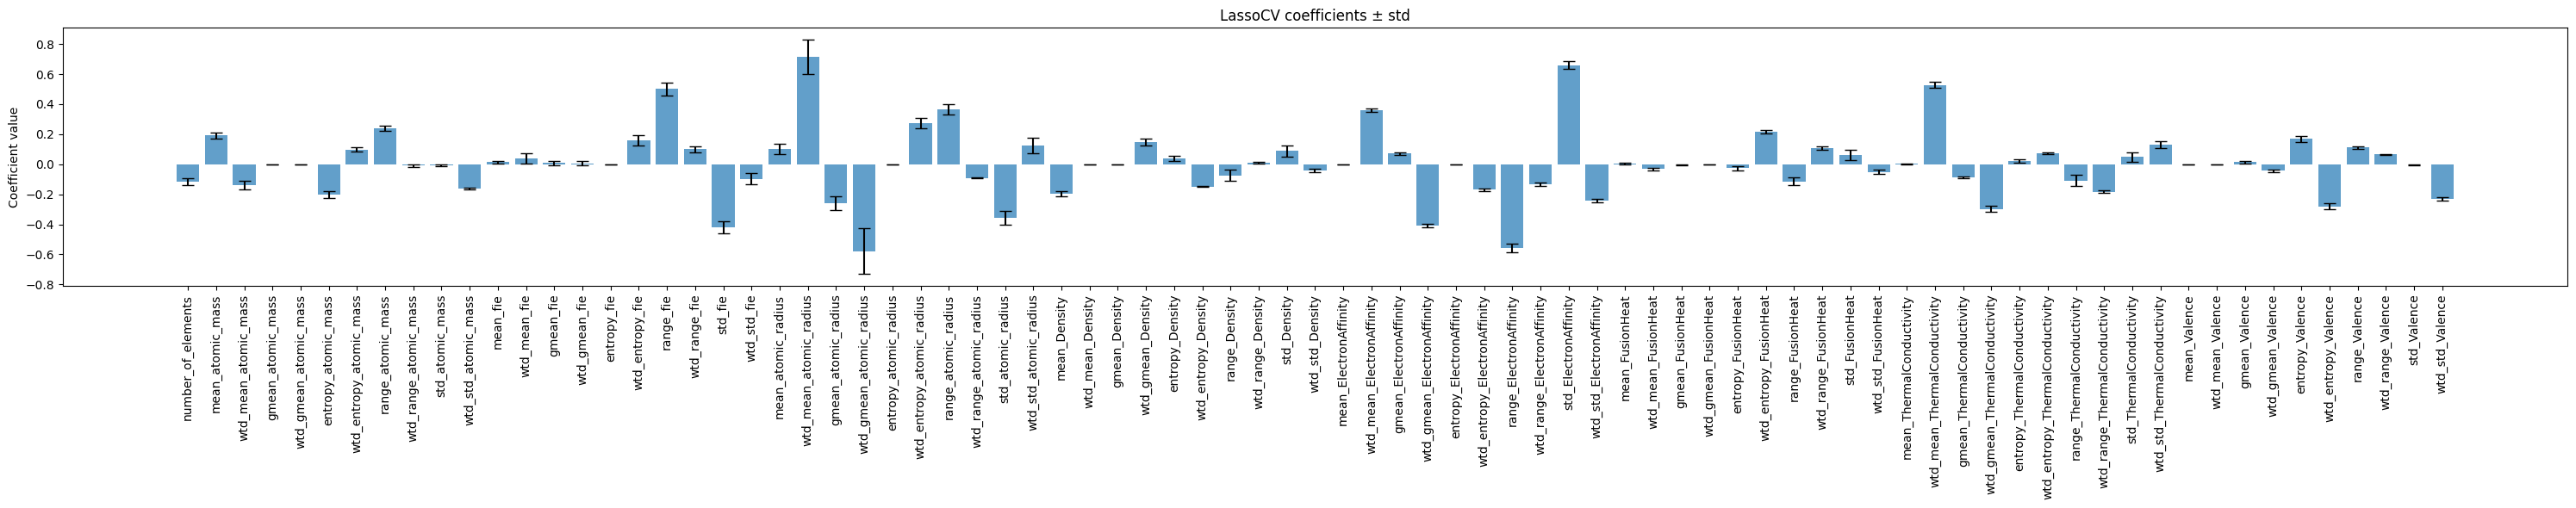

In [28]:
all_coeffs = []
all_alphas = []
all_mses = []

# for i in range(3,4):
for i in range(1, 6):
    train_df = pd.read_csv(f"../data/superconduct_{i}/train.csv")
    test_df = pd.read_csv(f"../data/superconduct_{i}/test.csv")

    print(train_df.shape, test_df.shape)

    model, best_alpha, test_mse = train_lasso_cv(train_df, test_df, cv=5)

    all_coeffs.append(model.coef_)
    all_alphas.append(best_alpha)
    all_mses.append(test_mse)

# Convert to arrays
coeff_array = np.array(all_coeffs)
alpha_array = np.array(all_alphas)
mse_array = np.array(all_mses)


lasso_mses = all_mses

lasso_coeffs = coeff_array

# Report mean ± std
print(f"Test MSE: {mse_array.mean():.4f} ± {mse_array.std():.4f}")
print(f"Selected alpha: {alpha_array.mean():.4f} ± {alpha_array.std():.4f}")

# Plot coefficients with error bars
coef_mean = coeff_array.mean(axis=0)
coef_std = coeff_array.std(axis=0)

feature_names = train_df.columns[:-1]  # assuming the last column is the target
plt.figure(figsize=(30, 6))
plt.bar(range(len(coef_mean)), coef_mean, yerr=coef_std, capsize=5, alpha=0.7)
plt.xticks(range(len(coef_mean)), feature_names, rotation=90)
plt.ylabel("Coefficient value")
plt.title("LassoCV coefficients ± std")
plt.tight_layout()
plt.savefig("../figs/lasso_superconduct_coefficients.pdf", dpi=300)
plt.show()

## Simple NN

In [3]:
def get_simplenn_mse(split, test_df):
    expr_name = f"predictions_simplenn_reg_superconduct_{split}.pt"
    nn_pred = torch.load(f"../ckpts/{expr_name}")
    nn_preds = []
    for li in nn_pred:
        for i in li:
            nn_preds.append(i)
    pred_nn = np.array(nn_preds)

    mse_loss_nn = mean_squared_error(test_df["target"], pred_nn)
    return mse_loss_nn

In [4]:
all_mses = []

for i in range(1, 6):
    train_df = pd.read_csv(f"../data/superconduct_{i}/train.csv")
    test_df = pd.read_csv(f"../data/superconduct_{i}/test.csv")
    val_df = pd.read_csv(f"../data/superconduct_{i}/val.csv")

    X_train = train_df.drop(columns="target").values
    y_train = train_df["target"].values.astype(float)
    X_val = val_df.drop(columns="target").values
    y_val = val_df["target"].values.astype(float)
    X_test = test_df.drop(columns="target").values
    y_test = test_df["target"].values.astype(float)

    test_mse = get_simplenn_mse(i, test_df)
    print(f"Simplenn test MSE for split {i}: {test_mse:.4f}")

    all_mses.append(test_mse)

nn_mses = all_mses
# Convert to arrays
mse_array = np.array(all_mses)

# Report mean ± std
print(f"Test MSE: {mse_array.mean():.4f} ± {mse_array.std():.4f}")

Simplenn test MSE for split 1: 0.1006
Simplenn test MSE for split 2: 0.0922
Simplenn test MSE for split 3: 0.0919
Simplenn test MSE for split 4: 0.1063
Simplenn test MSE for split 5: 0.1009
Test MSE: 0.0984 ± 0.0056


## LassoNet

In [31]:
def train_lassonet(train_df, val_df, test_df, hidden_dims=(64, 128)):
    X_train = train_df.drop("target", axis=1).values
    y_train = train_df["target"].values
    X_val = val_df.drop("target", axis=1).values
    y_val = val_df["target"].values
    X_test = test_df.drop("target", axis=1).values
    y_test = test_df["target"].values

    model = LassoNetRegressor(
        hidden_dims=hidden_dims,
        verbose=True,
        patience=(100, 5),
        random_state=42,
        torch_seed=42,
    )

    path = model.path(
        X_train,
        y_train,
        X_val=X_val,
        y_val=y_val,
        return_state_dicts=True,
    )

    best_record = min(path, key=lambda rec: rec.val_loss)

    lambda_, train_mse, val_mse, selected = (
        best_record.lambda_,
        best_record.loss,
        best_record.val_loss,
        best_record.selected,
    )

    print(
        f"Best λ: {lambda_:.3f}, Train MSE: {train_mse:.3f}, Val MSE: {val_mse:.3f}, Selected: {selected.sum()}"
    )

    # test
    model.load(best_record.state_dict)
    y_test_pred = model.predict(X_test)
    test_mse = mean_squared_error(y_test, y_test_pred)

    return test_mse

In [32]:
all_mses = []

for i in range(1, 6):
    train_df = pd.read_csv(f"../data/superconduct_{i}/train.csv")
    test_df = pd.read_csv(f"../data/superconduct_{i}/test.csv")
    val_df = pd.read_csv(f"../data/superconduct_{i}/val.csv")

    X_train = train_df.drop(columns="target").values
    y_train = train_df["target"].values.astype(float)
    X_val = val_df.drop(columns="target").values
    y_val = val_df["target"].values.astype(float)
    X_test = test_df.drop(columns="target").values
    y_test = test_df["target"].values.astype(float)

    test_mse = train_lassonet(train_df, val_df, test_df)

    all_mses.append(test_mse)

lassonet_mses = all_mses
# Convert to arrays
mse_array = np.array(all_mses)

# Report mean ± std
print(f"Test MSE: {mse_array.mean():.4f} ± {mse_array.std():.4f}")

Best λ: 0.000, Train MSE: 0.085, Val MSE: 0.109, Selected: 81
Best λ: 0.000, Train MSE: 0.087, Val MSE: 0.117, Selected: 81
Best λ: 0.000, Train MSE: 0.082, Val MSE: 0.116, Selected: 81
Best λ: 0.000, Train MSE: 0.082, Val MSE: 0.111, Selected: 81
Best λ: 0.000, Train MSE: 0.085, Val MSE: 0.120, Selected: 81
Test MSE: 0.1121 ± 0.0051


## NIMO

In [33]:
def select_best_nimo(split, val_df):
    min_mse = float("inf")
    best_penalty = None

    lasso_penalties = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]
    for penalty in lasso_penalties:
        ckpt_dir = f"../tb_logs/ar_reg_superconduct_{split}_lp_{penalty}/version_0/checkpoints/"
        ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
        model_ckpt = ckpt_files[0]

        model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
        X_tensor = torch.tensor(val_df.drop(columns="target").values).float()
        y_tensor = torch.tensor(val_df["target"].values).float()
        batch = {"features": X_tensor.to("cuda"), "target": y_tensor.to("cuda")}
        model.eval()
        pred, mse = model.predict_step(batch, None)

        if mse < min_mse:
            min_mse = mse
            best_penalty = penalty

    print(
        f"Best NIMO model for split {split} with lasso penalty {best_penalty} has val MSE: {min_mse}"
    )
    ckpt_dir = f"../tb_logs/ar_reg_superconduct_{split}_lp_{best_penalty}/version_0/checkpoints/"
    ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
    model_ckpt = ckpt_files[0]

    best_nimo = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
    return best_nimo


def test_nimo(model, test_df):
    X_tensor = torch.tensor(test_df.drop(columns="target").values).float()
    y_tensor = torch.tensor(test_df["target"].values).float()
    batch = {"features": X_tensor.to("cuda"), "target": y_tensor.to("cuda")}

    model.eval()
    pred, test_mse = model.predict_step(batch, None)
    return test_mse


def get_nimo_coeff(model, train_df, figsize=(10, 6), name=None):
    beta = model.beta.detach().cpu().numpy()

    beta_0 = model.beta_0.detach().cpu().numpy()
    assert beta_0 == 0, "Intercept should be zero for NIMO"

    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    # plot first FC layer weights
    plt.figure(figsize=figsize)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../figs/{name}_fc_weights.pdf", dpi=300)
    plt.close()
    plt.show()

    return beta

==> training with noise_injection=True
Predict MSE: 0.10089236497879028
==> training with noise_injection=True
Predict MSE: 0.09792542457580566
==> training with noise_injection=True
Predict MSE: 0.09747765213251114
==> training with noise_injection=True
Predict MSE: 0.10536248981952667
==> training with noise_injection=True
Predict MSE: 0.1114293783903122
==> training with noise_injection=True
Predict MSE: 0.15060009062290192
==> training with noise_injection=True
Predict MSE: 0.18113179504871368
Best NIMO model for split 1 with lasso penalty 0.001 has val MSE: 0.09747765213251114
==> training with noise_injection=True
Predict MSE: 0.1121368333697319
NIMO Test MSE: 0.1121368333697319
==> training with noise_injection=True
Predict MSE: 0.10730260610580444
==> training with noise_injection=True
Predict MSE: 0.10345099866390228
==> training with noise_injection=True
Predict MSE: 0.10272078961133957
==> training with noise_injection=True
Predict MSE: 0.10984233766794205
==> training with 

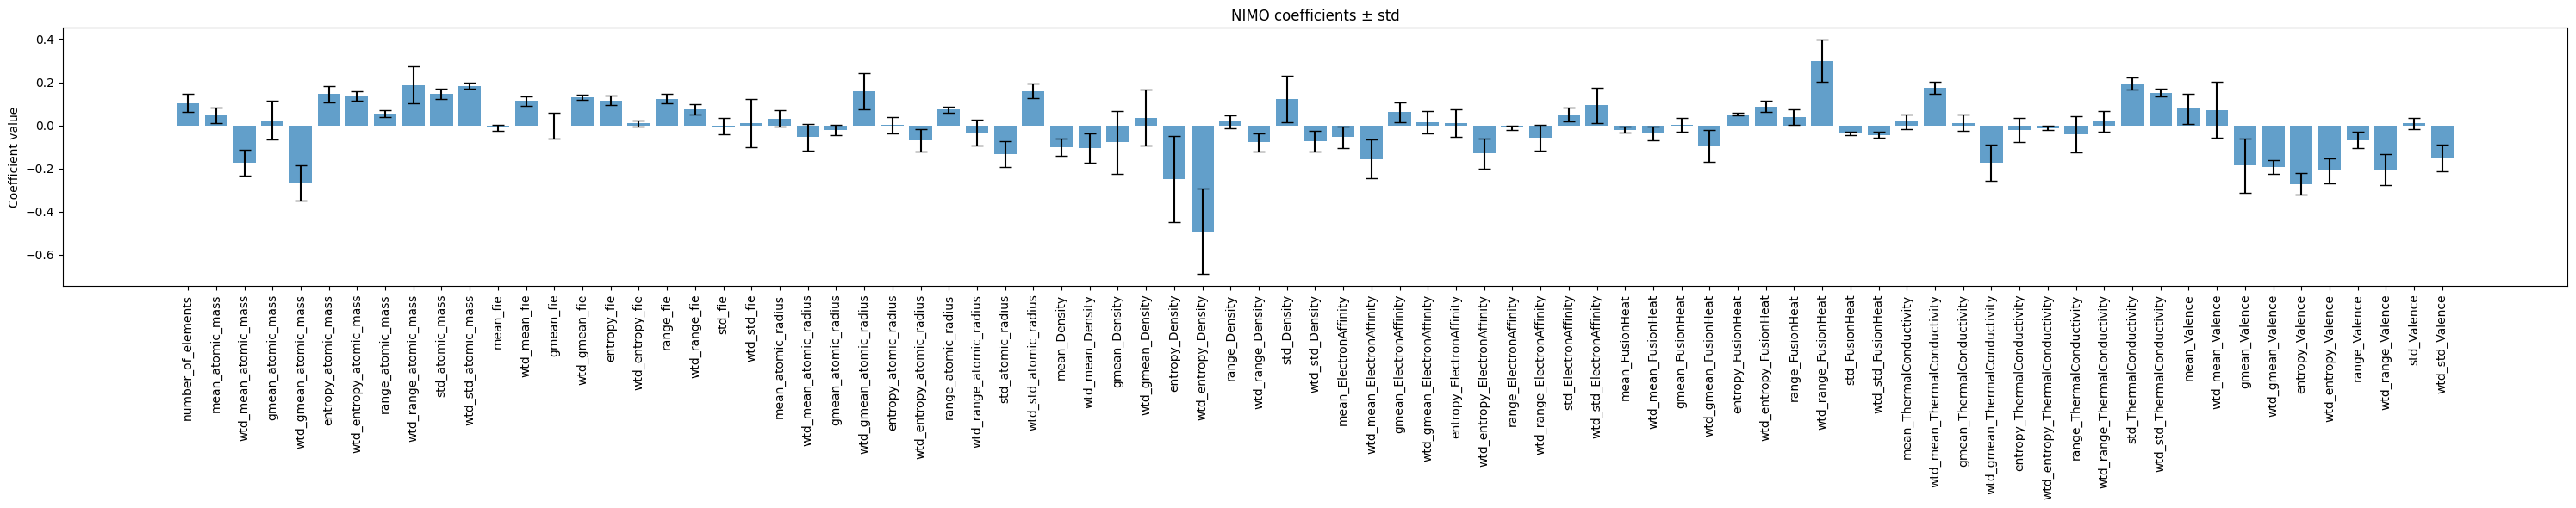

In [44]:
all_coeffs = []
all_mses = []

for i in range(1, 6):
    train_df = pd.read_csv(f"../data/superconduct_{i}/train.csv")
    test_df = pd.read_csv(f"../data/superconduct_{i}/test.csv")
    val_df = pd.read_csv(f"../data/superconduct_{i}/val.csv")

    nimo = select_best_nimo(i, val_df)
    mse_nimo = test_nimo(nimo, test_df)
    print(f"NIMO Test MSE: {mse_nimo}")

    nimo_coeff_ = get_nimo_coeff(nimo, train_df, figsize=(10, 6), name=f"superconduct_{i}_nimo")

    all_coeffs.append(nimo_coeff_)
    all_mses.append(mse_nimo.detach().cpu().numpy().item())

# Convert to arrays
coeff_array = np.array(all_coeffs)
nimo_mses = all_mses
mse_array = np.array(all_mses)

# Report mean ± std
print(f"Test MSE: {mse_array.mean():.4f} ± {mse_array.std():.4f}")

# Plot coefficients with error bars
coef_mean = coeff_array.mean(axis=0)
coef_std = coeff_array.std(axis=0)

nimo_coeffs = coeff_array

feature_names = train_df.columns[:-1]  # assuming the last column is the target
plt.figure(figsize=(30, 6))
plt.bar(range(len(coef_mean)), coef_mean, yerr=coef_std, capsize=5, alpha=0.7)
plt.xticks(range(len(coef_mean)), feature_names, rotation=90)
plt.ylabel("Coefficient value")
plt.title("NIMO coefficients ± std")
plt.tight_layout()
plt.savefig("../figs/nimo_superconduct_coefficients.pdf", dpi=300)
plt.show()

In [35]:
def to_long_df(coeffs, method_name, feature_names):
    df = pd.DataFrame(coeffs, columns=feature_names)
    df = df.melt(var_name="Feature", value_name="Coefficient")
    df["Method"] = method_name
    return df


def plot_coeffs(lasso_coeffs, nimo_coeffs, train_df):
    feats = train_df.columns[:-1]

    df_lasso_d = to_long_df(lasso_coeffs, "Lasso", feats)
    df_nimo_d = to_long_df(nimo_coeffs, "NIMO", feats)

    # Combine into one DataFrame
    df_all = pd.concat([df_lasso_d, df_nimo_d], ignore_index=True)

    # Plot
    plt.figure(figsize=(20, 5))
    sns.barplot(
        x="Feature",
        y="Coefficient",
        hue="Method",
        data=df_all,
        capsize=0.4,
        err_kws={"linewidth": 1.5},
        palette="muted",
    )
    plt.title("Baseline Marginal Effects")
    plt.ylabel("Value")
    plt.xticks(rotation=90)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(title="Method")
    plt.tight_layout()
    plt.savefig("../figs/superconduct_coeff.pdf", dpi=300)
    plt.show()

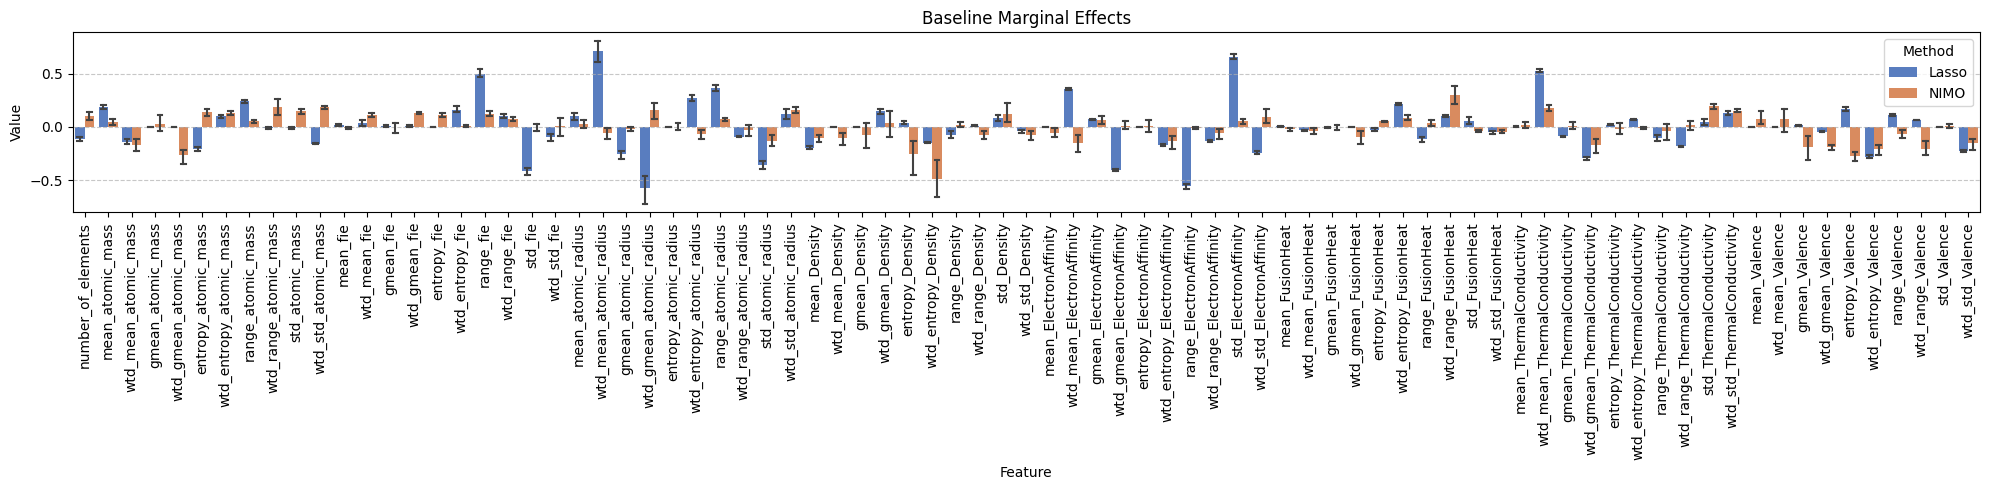

In [36]:
train_df = pd.read_csv(f"../data/superconduct_1/train.csv")
plot_coeffs(lasso_coeffs, nimo_coeffs, train_df)

## NAM

Fold 1 Test MSE: 0.2061</br>
Fold 2 Test MSE: 0.1643</br>
Fold 3 Test MSE: 0.2091</br>
Fold 4 Test MSE: 0.2106</br>
Fold 5 Test MSE: 0.1725</br>
Test MSE: 0.1925 ± 0.0199

In [37]:
nam_mses = [0.2061, 0.1643, 0.2091, 0.2106, 0.1725]

### IMN

In [38]:
imn_mses = [
    0.19442410644350525,
    0.18199155799448902,
    0.1859070036994081,
    0.19701833161720142,
    0.18704192979291817,
]

mse_array = np.array(imn_mses)
print(f"Test MSE: {mse_array.mean():.4f} ± {mse_array.std():.4f}")

Test MSE: 0.1893 ± 0.0056


In [6]:
def plot_mses(lasso_mses, lassonet_mses, simplenn_mses, nimo_mses, nam_mses, imn_mses):
    df_mses = pd.DataFrame(
        {
            "Lasso": lasso_mses,
            "NN": simplenn_mses,
            "NAM": nam_mses,
            "IMN": imn_mses,
            "LassoNet": lassonet_mses,
            "NIMO": nimo_mses,
        }
    )

    print(df_mses)
    # compute mean and std
    print("Mean and Std of MSEs:")
    print(df_mses.mean().apply(lambda x: f"{x:.3f}"))
    print(df_mses.std().apply(lambda x: f"{x:.3f}"))

    sns.color_palette("dark")
    plt.figure(figsize=(4, 5))
    sns.boxplot(data=df_mses, palette="muted", whis=[0, 100], showfliers=False)
    # plt.title('Test MSE of Different Methods')
    # plt.xlabel('Method')
    plt.ylabel("Test MSE")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.savefig("../figs/superconduct_mse.pdf", dpi=300)
    plt.show()

      Lasso      NN     NAM       IMN  LassoNet      NIMO
0  0.278354  0.1006  0.2061  0.194424  0.115404  0.112137
1  0.262942  0.0922  0.1643  0.181992  0.106567  0.090758
2  0.275779  0.0919  0.2091  0.185907  0.106132  0.094656
3  0.279795  0.1063  0.2106  0.197018  0.119300  0.113211
4  0.276878  0.1009  0.1725  0.187042  0.113105  0.101053
Mean and Std of MSEs:
Lasso       0.275
NN          0.098
NAM         0.193
IMN         0.189
LassoNet    0.112
NIMO        0.102
dtype: object
Lasso       0.007
NN          0.006
NAM         0.022
IMN         0.006
LassoNet    0.006
NIMO        0.010
dtype: object


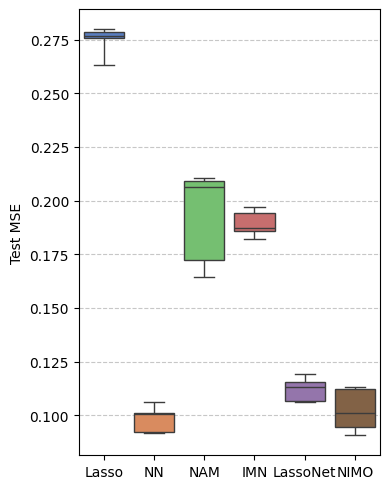

In [7]:
lasso_mses = [0.278354, 0.262942, 0.275779, 0.279795, 0.276878]
nn_mses = [0.1006, 0.0922, 0.0919, 0.1063, 0.1009]
nam_mses = [0.2061, 0.1643, 0.2091, 0.2106, 0.1725]
imn_mses = [0.194424, 0.181992, 0.185907, 0.197018, 0.187042]
lassonet_mses = [0.115404, 0.106567, 0.106132, 0.119300, 0.113105]
nimo_mses = [0.112137, 0.090758, 0.094656, 0.113211, 0.101053]
plot_mses(lasso_mses, lassonet_mses, nn_mses, nimo_mses, nam_mses, imn_mses)